<a href="https://colab.research.google.com/github/nazianusrat/Counter-numbers/blob/main/Data_that_worked.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.ensemble import RandomForestClassifier

# CREATE DATASET
data = {
    "Study_ID": ["S1","S2","S3","S4","S5","S6","S7","S8","S9","S10","S11","S12","S13","S14","S15"],
    "Intervention_Type": [
        "Behavioral","Behavioral","Family","Device","Device","App",
        "School","Family","Family","Physical","Physical","Mindfulness",
        "Mindfulness","AI","App"
    ],
    "Duration_Weeks": [3,3,6,4,4,6,8,8,12,10,8,6,6,4,8],
    "Self_Monitoring": [1,1,0,0,0,0,0,1,1,0,0,1,1,1,1],
    "Parental_Involvement": [0,0,1,0,0,0,1,1,1,0,0,0,0,0,0],
    "Tech_Based": [0,0,0,1,1,1,0,0,0,0,0,0,0,1,1],
    "Physical_Activity": [0,0,0,0,0,0,0,1,0,1,1,0,0,0,0],
    "ScreenTime_Reduction_Min": [120,60,180,38,45,153,90,155,40,60,45,30,25,35,50],
    "Effect_Size": [0.27,0.31,0.72,0.20,0.25,0.45,1.47,0.80,0.53,3.11,0.40,0.35,0.41,0.20,0.30],
    "Effectiveness_Label": ["High","Medium","High","Medium","Medium","High","High","High","High","High","Medium","Medium","Medium","Medium","Medium"]
}

df = pd.DataFrame(data)
print("Data created! Shape:", df.shape)
print(df.head())


Data created! Shape: (15, 10)
  Study_ID Intervention_Type  Duration_Weeks  Self_Monitoring  \
0       S1        Behavioral               3                1   
1       S2        Behavioral               3                1   
2       S3            Family               6                0   
3       S4            Device               4                0   
4       S5            Device               4                0   

   Parental_Involvement  Tech_Based  Physical_Activity  \
0                     0           0                  0   
1                     0           0                  0   
2                     1           0                  0   
3                     0           1                  0   
4                     0           1                  0   

   ScreenTime_Reduction_Min  Effect_Size Effectiveness_Label  
0                       120         0.27                High  
1                        60         0.31              Medium  
2                       180         0.72 

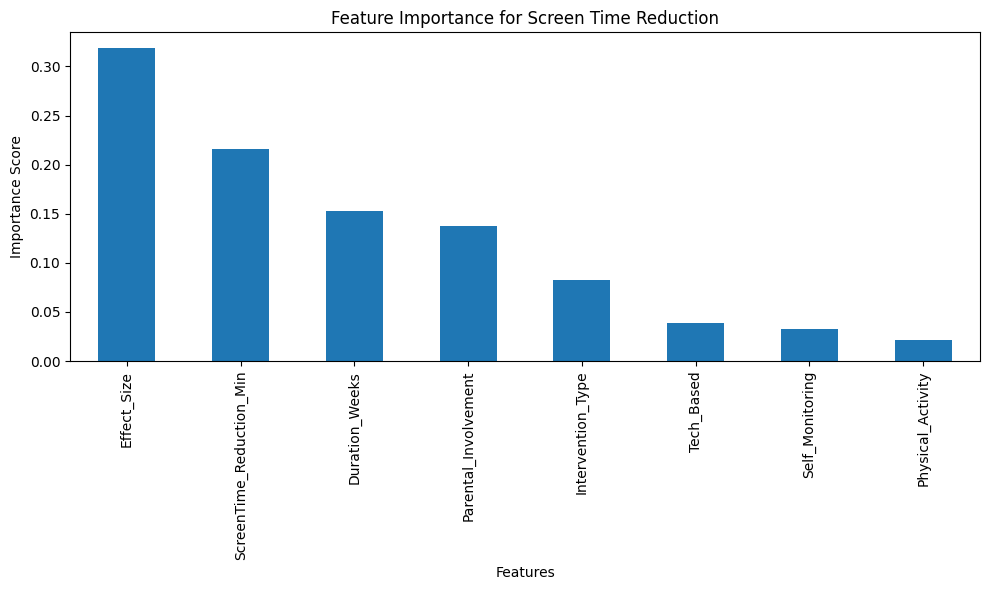

Effect_Size                 0.318726
ScreenTime_Reduction_Min    0.215485
Duration_Weeks              0.153223
Parental_Involvement        0.137657
Intervention_Type           0.082662
Tech_Based                  0.038278
Self_Monitoring             0.032266
Physical_Activity           0.021702
dtype: float64


In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.ensemble import RandomForestClassifier
from sklearn.preprocessing import LabelEncoder

# Encode categorical columns
le_intervention = LabelEncoder()
df["Intervention_Type"] = le_intervention.fit_transform(df["Intervention_Type"])

# Encode target labels
df["Effectiveness_Label"] = df["Effectiveness_Label"].map({
    "Low": 0,
    "Medium": 1,
    "High": 2
})

# Remove rows with NaN in Effectiveness_Label
df = df.dropna(subset=["Effectiveness_Label"])

# Features and target
X = df.drop(columns=["Study_ID", "Effectiveness_Label"])
y = df["Effectiveness_Label"]

# Train Random Forest
model = RandomForestClassifier(n_estimators=100, random_state=42)
model.fit(X, y)

# Feature importance
importances = pd.Series(model.feature_importances_, index=X.columns).sort_values(ascending=False)

# Plot results
plt.figure(figsize=(10, 6))
importances.plot(kind="bar")
plt.title("Feature Importance for Screen Time Reduction")
plt.ylabel("Importance Score")
plt.xlabel("Features")
plt.tight_layout()
plt.show()

# Print the importances
print(importances)
